# Experiment 01:  Model Validation

## Objective

The objective of this experiment is to implement and compare three methods for pricing a European call option:

1. Black–Scholes closed-form solution
2. Numerical integration of the risk-neutral expected payoff
3. Monte Carlo estimation of the risk-neutral expected payoff

The Black–Scholes analytical price will serve as the reference value against which the numerical methods are evaluated.

## Experimental Hypothesis

Under identical model assumptions and market parameters, numerical integration should reproduce the Black–Scholes price up to numerical integration error. Monte Carlo estimates should converge toward the same theoretical price as the number of simulations increases.

## Model Parameters

We begin with a hypothetical option:

- Initial asset price: \(S_0 = 100\)
- Strike price: \(K = 100\)
- Time to expiration: \(T = 1\) year
- Risk-free interest rate: \(r = 0.05\)
- Annualized volatility: ($sigma = 0.20$)

## Evaluation Metrics

- Estimated option price
- Absolute error relative to the analytical price
- Relative error
- Monte Carlo estimation variability

All three methods will use the same parameters to ensure a fair comparison.

In [3]:
import torch
import torch.nn as nn
import numpy as np
import scipy,  matplotlib, pandas

In [2]:
from abc import ABC, abstractmethod

class QuantLab(ABC):
    def __init__(self, *args, **kwargs):
        pass

    @abstractmethod
    def forward(self, *args, **kwargs):
        pass

    def __call__(self, *args, **kwargs):
        return self.forward(*args, **kwargs)

## Base Model: Black Scholes Call Equation

In [ ]:
import numpy as np
from scipy.stats import norm

class BlackScholesCall(QuantLab):
    """
    A very basic Implementation of Black Scholes Equation
    """
    def __init__(self, K: float, sigma: float, T: float, r: float):
        """
        K: Strike price
        sigma: volatility in the asset
        T: Remaining Time period in years
        r: risk free interest rate
        """
        super().__init__()
        self.K = K
        self.r = r
        self.sigma = sigma
        self.T = T

    def forward(self, S0: np.ndarray):
        """
        S0: current price of the asset
        Given any current price and the model's parameter, we can estimate the Price of European call option, using Black Scholes Call Equation
        """
        S0 = np.asarray(S0, dtype=np.float64)

        d1 = (np.log(S0 / self.K) + self.T * (self.r + (self.sigma ** 2) / 2)) / (self.sigma * np.sqrt(self.T))
        d2 = d1 - self.sigma * np.sqrt(self.T)

        C0 = S0 * norm.cdf(d1) - self.K * np.exp(-self.r * self.T) * norm.cdf(d2)

        # 1st term is, Expected value of the asset over time period T, where the call option makes money, i.e S_T > K
        # 2nd term is, weighted average of Strike Price where the call option makes the money, i.e S_T > K
        return C0

In [29]:
S0 = 100
K = 100
T = 1.0
r = 0.05
sigma = 0.20

black_scholes_model = BlackScholesCall(K = K, T = T, r = r, sigma = sigma)
price = black_scholes_model(S0)


print(f"Black Scholes Option Price = INR {price:.4f}")

Black Scholes Option Price = INR 10.4506


---

## Numerical Integration Method
Under the risk-neutral measure, the terminal stock price is

$$
S_T = S_0 \exp\left[\left(r-\frac{\sigma^2}{2}\right)T+\sigma\sqrt{T}Z\right],
\qquad Z\sim\mathcal{N}(0,1)
$$

The European call payoff at expiration is

$$
\max(S_T-K,0)
$$

Discounting its expected payoff back to the present gives

$$
C_0=e^{-rT}\mathbb{E}^{Q}\left[\max(S_T-K,0)\right]
$$

Since \(Z\) follows a standard normal distribution, we can express this expectation as an integral:

$$
C_0=e^{-rT}\int_{-\infty}^{\infty}
\max\left(
S_0e^{(r-\frac{1}{2}\sigma^2)T+\sigma\sqrt{T}z}-K,
0
\right)\phi(z)\,dz
$$

where the standard normal probability density function is

$$
\phi(z)=\frac{1}{\sqrt{2\pi}}e^{-z^2/2}
$$


In [ ]:
from scipy.integrate import quad

class NumericalIntegrationCall(QuantLab):
    """
    A very basic Implementation of Numerical Integration method
    """
    def __init__(self, K: float, sigma: float, T: float, r: float):
        """
        K: Strike price
        sigma: volatility in the asset
        T: Remaining Time period in years
        r: risk free interest rate
        """
        super().__init__()
        self.K = K
        self.r = r
        self.sigma = sigma
        self.T = T

    def forward(self, S0: np.ndarray):
        """
        S0: current price of the asset
        Given any current price and the model's parameter, we can estimate the Price of European call option, using Numerical Integration
        """
        S0 = np.asarray(S0, dtype=np.float64)

        def integrand(z):
            """
            calculates the integrand, and i'll use scipy's integrate.quad to eval to this integrand
            """
            ST = S0 * np.exp((self.r - 0.5 * (self.sigma**2))* self.T + self.sigma * np.sqrt(self.T) * z)
            payoff = max(ST - self.K, 0.0)
            pdf = np.exp(-0.5 * z**2) / (np.sqrt(2 * np.pi)) # Standard normal probability density
            return payoff * pdf

        expected_payoff, _ = quad(
            integrand,
            -np.inf,
            np.inf,
        )

        C0 = np.exp(-self.r * self.T) * expected_payoff
        return C0

In [74]:
model = NumericalIntegrationCall(
    K=100,
    sigma=0.20,
    T=1.0,
    r=0.05,
)

price = model.forward(S0=100)
print(f"Numerical Integration's Option Price: {price:.6f}")


Numerical Integration's Option Price: 10.450584


---

## Monte Carlo simulation


Under the risk-neutral measure, the terminal stock price is

$$
S_T^{(i)} = S_0 \exp\left[
\left(r-\frac{\sigma^2}{2}\right)T
+\sigma\sqrt{T}Z_i
\right],
\qquad Z_i\overset{\text{i.i.d.}}{\sim}\mathcal{N}(0,1)
$$

The European call payoff for the \(i\)-th simulation is

$$
C_T^{(i)}=\max\left(S_T^{(i)}-K,0\right)
$$

The theoretical option price is the discounted risk-neutral expected payoff:

$$
C_0=e^{-rT}\mathbb{E}^{Q}\left[\max(S_T-K,0)\right]
$$

Monte Carlo simulation approximates this expectation using \(M\) independent simulations:

$$
\widehat{C}_0=\frac{e^{-rT}}{M}
\sum_{i=1}^{M}\max\left(S_T^{(i)}-K,0\right)
$$

Substituting the simulated terminal stock price gives

$$
\widehat{C}_0=\frac{e^{-rT}}{M}
\sum_{i=1}^{M}
\max\left(
S_0e^{(r-\frac{1}{2}\sigma^2)T+\sigma\sqrt{T}Z_i}-K,
0
\right)
$$

As the number of simulations \(M\) increases, the Monte Carlo estimate converges to the theoretical option price under the model assumptions:

$$
\widehat{C}_0\xrightarrow[M\to\infty]{\text{a.s.}}C_0
$$


In [ ]:
class MonteCarloCall(QuantLab):
    """
    A very basic Implementation of Numerical Integration method
    """
    def __init__(self, K: float, sigma: float, T: float, r: float):
        """
        K: Strike price
        sigma: volatility in the asset
        T: Remaining Time period in years
        r: risk free interest rate
        """
        super().__init__()
        self.K = K
        self.r = r
        self.sigma = sigma
        self.T = T

    def forward(self, S0: np.ndarray, steps: int):
        """
        S0: current price of the asset
        Given any current price and the model's parameter, we can estimate the Price of European call option, using Numerical Integration
        """
        S0 = np.asarray(S0, dtype=np.float64)
        z = np.random.randn(steps) # Z drawn from Stand Normal Gaussian
        ST = S0 * np.exp((self.r - 0.5 * (self.sigma**2) )* self.T + self.sigma * np.sqrt(self.T) * z)
        payoff = np.maximum(ST - self.K, 0)

        expected_payoff = np.mean(payoff)
        C0 = np.exp(-self.r * self.T) * expected_payoff
        return C0

In [72]:
model = MonteCarloCall(
    K=100,
    sigma=0.20,
    T=1.0,
    r=0.05,
)

price = model.forward(S0=100, steps = 1000000)
print(f"Monte carlo's Option Price: {price:.6f}")


Monte carlo's Option Price: 10.491095


## Results

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

sns.set_theme(style="whitegrid", context="notebook")

# Shared parameters
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

bs = BlackScholesCall(K=K, sigma=sigma, T=T, r=r)
ni = NumericalIntegrationCall(K=K, sigma=sigma, T=T, r=r)
mc = MonteCarloCall(K=K, sigma=sigma, T=T, r=r)

reference_price = float(bs.forward(S0))
integration_price = float(ni.forward(S0))
mc_price = float(mc.forward(S0, steps=1_000_000))

results = pd.DataFrame({
    "Method": [
        "Black-Scholes",
        "Numerical Integration",
        "Monte Carlo",
    ],
    "Option Price": [
        reference_price,
        integration_price,
        mc_price,
    ],
})

results["Absolute Error"] = np.abs(
    results["Option Price"] - reference_price
)

display(results.round(8))

,Method,Option Price,Absolute Error
0,Black-Scholes,10.450584,0.000000
1,Numerical Integration,10.450584,0.000000
2,Monte Carlo,10.456182,0.005599


# Model agreement

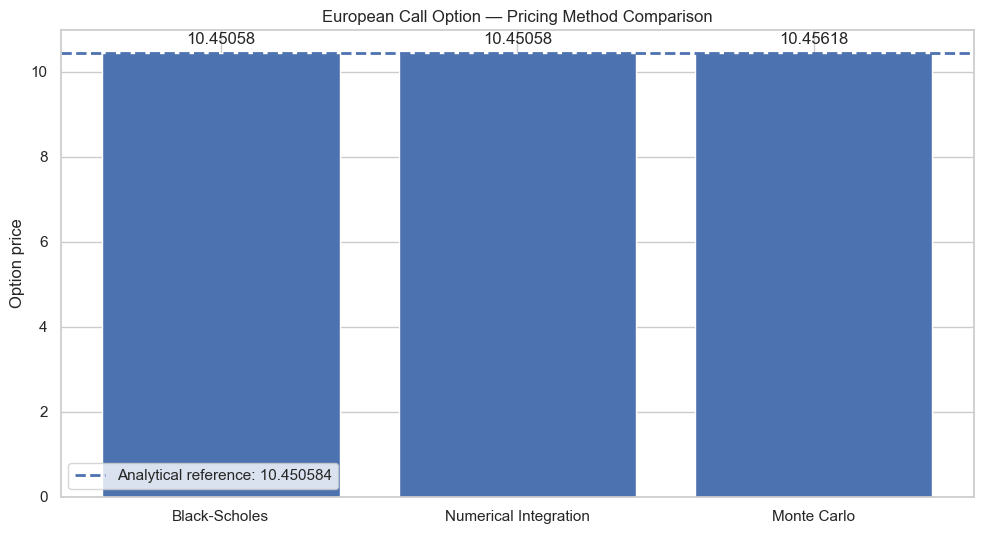

In [76]:
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    results["Method"],
    results["Option Price"],
)

ax.axhline(
    reference_price,
    linestyle="--",
    linewidth=2,
    label=f"Analytical reference: {reference_price:.6f}",
)

ax.set_title("European Call Option — Pricing Method Comparison")
ax.set_ylabel("Option price")
ax.legend()
ax.bar_label(bars, fmt="%.5f", padding=4)

plt.tight_layout()
plt.show()

# Monte Carlo convergence

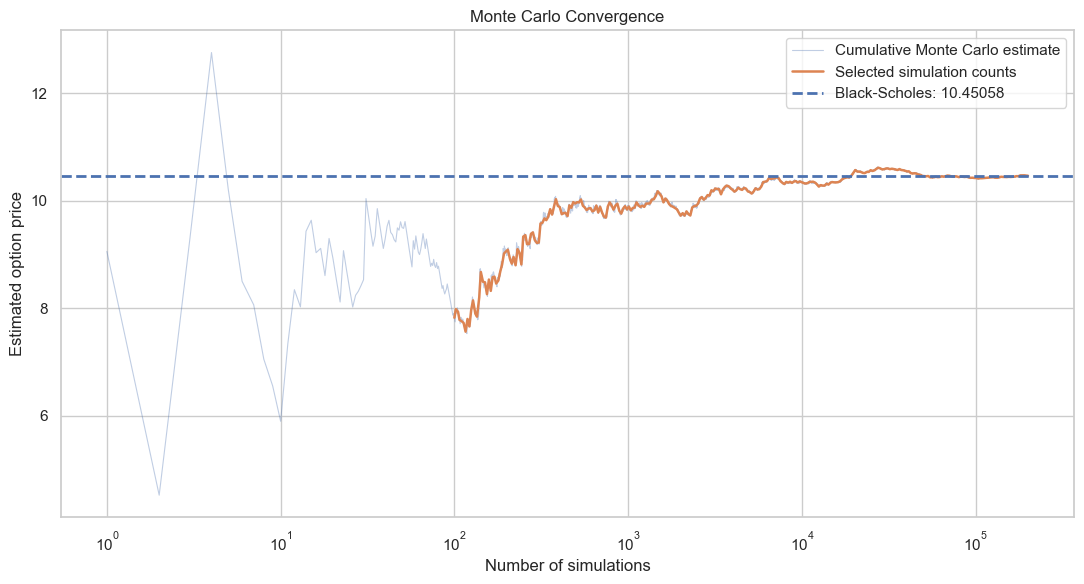

In [77]:
rng = np.random.default_rng(42)

M = 200_000
z = rng.standard_normal(M)

ST = S0 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * z
)

payoffs = np.maximum(ST - K, 0.0)

# Each entry is the estimate using samples 1 through i
estimates = np.exp(-r * T) * np.cumsum(payoffs) / np.arange(1, M + 1)

sample_counts = np.unique(
    np.logspace(2, np.log10(M), 300).astype(int)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    np.arange(1, M + 1),
    estimates,
    alpha=0.35,
    linewidth=0.8,
    label="Cumulative Monte Carlo estimate",
)

ax.plot(
    sample_counts,
    estimates[sample_counts - 1],
    linewidth=1.8,
    label="Selected simulation counts",
)

ax.axhline(
    reference_price,
    linestyle="--",
    linewidth=2,
    label=f"Black-Scholes: {reference_price:.5f}",
)

ax.set_xscale("log")
ax.set_xlabel("Number of simulations")
ax.set_ylabel("Estimated option price")
ax.set_title("Monte Carlo Convergence")
ax.legend()

plt.tight_layout()
plt.show()

## Volatility sensitivity

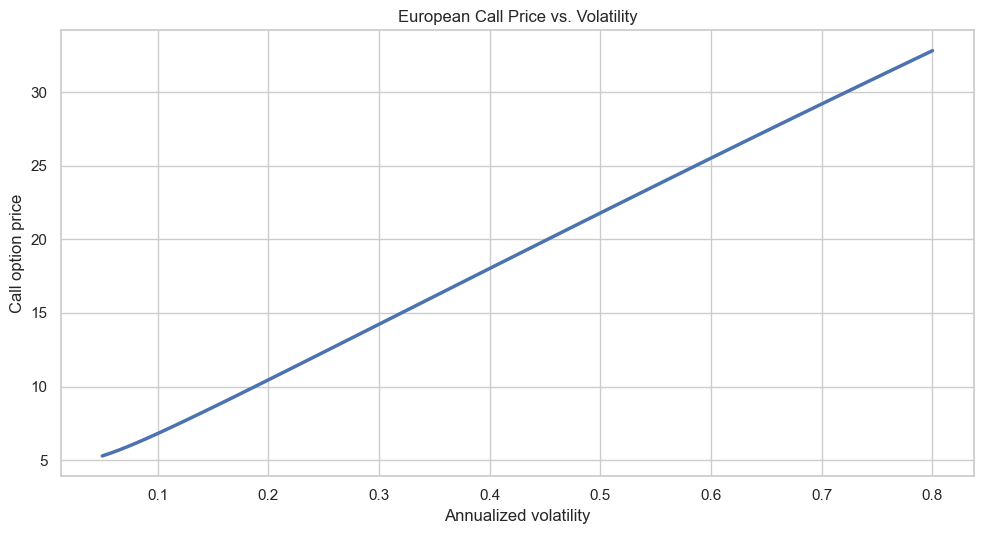

In [78]:
volatilities = np.linspace(0.05, 0.80, 100)

prices = np.array([
    BlackScholesCall(
        K=K, sigma=vol, T=T, r=r
    ).forward(S0)
    for vol in volatilities
])

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(volatilities, prices, linewidth=2.5)

ax.set_xlabel("Annualized volatility")
ax.set_ylabel("Call option price")
ax.set_title("European Call Price vs. Volatility")

plt.tight_layout()
plt.show()

# Two-dimensional option price surface

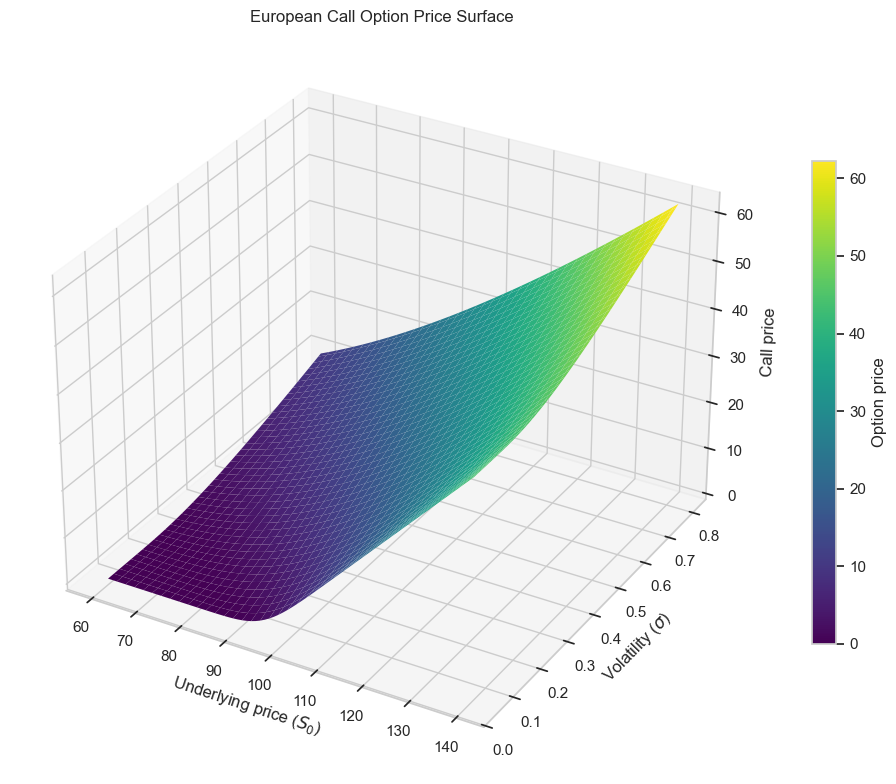

In [79]:
from scipy.stats import norm

S_values = np.linspace(60, 140, 80)
vol_values = np.linspace(0.05, 0.80, 80)

S_grid, vol_grid = np.meshgrid(S_values, vol_values)

d1 = (
    np.log(S_grid / K)
    + (r + 0.5 * vol_grid**2) * T
) / (vol_grid * np.sqrt(T))

d2 = d1 - vol_grid * np.sqrt(T)

price_grid = (
    S_grid * norm.cdf(d1)
    - K * np.exp(-r * T) * norm.cdf(d2)
)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    S_grid,
    vol_grid,
    price_grid,
    cmap="viridis",
    edgecolor="none",
    antialiased=True,
)

ax.set_xlabel("Underlying price ($S_0$)")
ax.set_ylabel("Volatility ($\\sigma$)")
ax.set_zlabel("Call price")
ax.set_title("European Call Option Price Surface")

fig.colorbar(surface, ax=ax, shrink=0.65, label="Option price")
plt.tight_layout()
plt.show()

# Error analysis

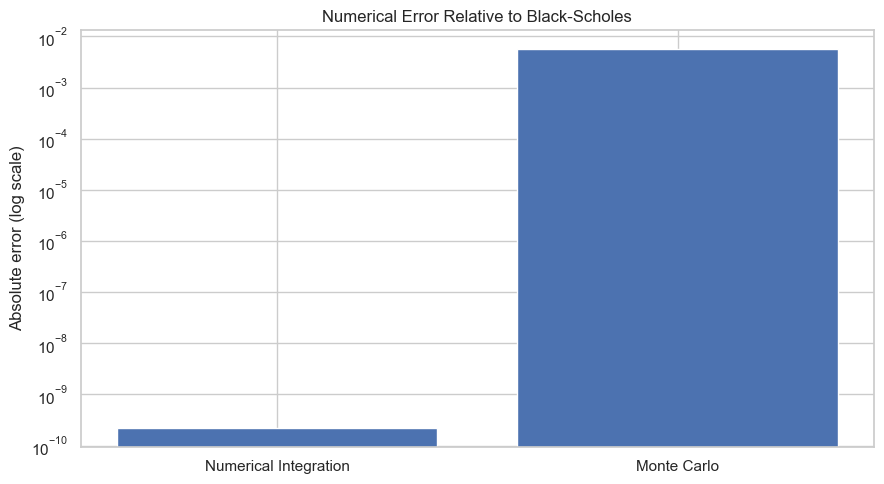

In [80]:
fig, ax = plt.subplots(figsize=(9, 5))

error_data = results[results["Method"] != "Black-Scholes"]

ax.bar(
    error_data["Method"],
    error_data["Absolute Error"],
)

ax.set_yscale("log")
ax.set_ylabel("Absolute error (log scale)")
ax.set_title("Numerical Error Relative to Black-Scholes")

plt.tight_layout()
plt.show()

# Black–Scholes, Numerical Integration, and Monte Carlo method Comparisions

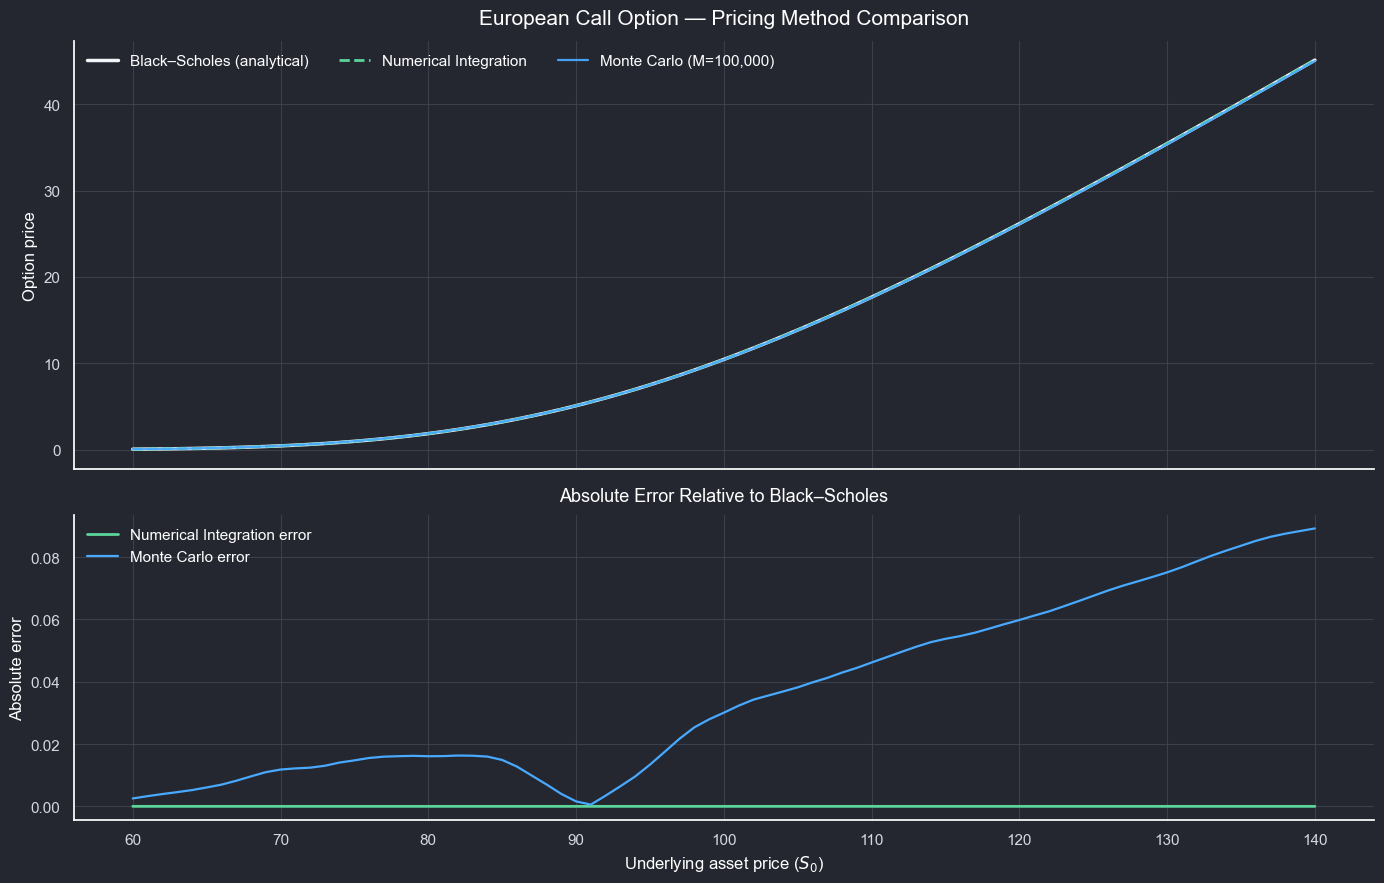

In [82]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Assumes your three model classes are already defined.

# -----------------------------
# 1. Experimental configuration
# -----------------------------
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

S_values = np.linspace(60, 140, 81)

bs = BlackScholesCall(K=K, sigma=sigma, T=T, r=r)
ni = NumericalIntegrationCall(K=K, sigma=sigma, T=T, r=r)
mc = MonteCarloCall(K=K, sigma=sigma, T=T, r=r)

# Use common random numbers across all S0 values.
# This reduces noise in comparisons between Monte Carlo estimates.
rng = np.random.default_rng(42)
M = 100_000
z = rng.standard_normal(M)

# -----------------------------
# 2. Calculate option prices
# -----------------------------
bs_prices = np.array([
    bs.forward(S0) for S0 in S_values
])

ni_prices = np.array([
    ni.forward(S0) for S0 in S_values
])

def monte_carlo_call_price(S0):
    ST = S0 * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * z
    )
    payoff = np.maximum(ST - K, 0.0)
    return np.exp(-r * T) * np.mean(payoff)

mc_prices = np.array([
    monte_carlo_call_price(S0) for S0 in S_values
])

# Absolute errors relative to analytical reference
ni_error = np.abs(ni_prices - bs_prices)
mc_error = np.abs(mc_prices - bs_prices)

# -----------------------------
# 3. Dark research plotting theme
# -----------------------------
plt.style.use("dark_background")

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1.4, 1]},
)

fig.patch.set_facecolor("#242730")

for ax in (ax1, ax2):
    ax.set_facecolor("#242730")
    ax.grid(True, color="#414650", linewidth=0.8, alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(colors="#d5d8df")

# -----------------------------
# 4. Panel 1: Option price curves
# -----------------------------
ax1.plot(
    S_values, bs_prices,
    color="#f2f4f8",
    linewidth=2.5,
    label="Black–Scholes (analytical)",
)

ax1.plot(
    S_values, ni_prices,
    color="#5bd49a",
    linewidth=2,
    linestyle="--",
    label="Numerical Integration",
)

ax1.plot(
    S_values, mc_prices,
    color="#48a9ff",
    linewidth=1.6,
    alpha=0.95,
    label=f"Monte Carlo (M={M:,})",
)

ax1.set_title(
    "European Call Option — Pricing Method Comparison",
    fontsize=15,
    pad=12,
)
ax1.set_ylabel("Option price")
ax1.legend(frameon=False, ncol=3, loc="upper left")

# -----------------------------
# 5. Panel 2: Absolute pricing error
# -----------------------------
ax2.plot(
    S_values, ni_error,
    color="#5bd49a",
    linewidth=2,
    label="Numerical Integration error",
)

ax2.plot(
    S_values, mc_error,
    color="#48a9ff",
    linewidth=1.6,
    label="Monte Carlo error",
)

ax2.set_xlabel("Underlying asset price ($S_0$)")
ax2.set_ylabel("Absolute error")
ax2.set_title(
    "Absolute Error Relative to Black–Scholes",
    fontsize=13,
    pad=10,
)
ax2.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()
